**Fetal Head Ultrasound: U-Net Segmentation**

This notebook trains a U-Net to find the fetal head in each ultrasound image. It uses the loader in *src/dataset.py*, the masks and the train, validation and test split made in notebook 01, without changing any of them.

The plan has five steps:

1. Build a plain U-Net, written out layer by layer in PyTorch.
2. Train it on the train split and use the validation split to pick the best epoch.
3. Use the validation split again to pick the probability threshold that turns the model output into a 0/1 mask.
4. Score the test split once, with Dice, IoU and the head circumference error in mm.
5. Save the predicted masks so the measurement notebook can use them.

Run notebook 01 first. On Colab, pick a GPU runtime (Runtime > Change runtime type > T4 GPU).

In [1]:
!pip install -q "albumentations>=1.4"

In [2]:
import os
import subprocess
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

plt.rcParams["figure.dpi"] = 70  # keeps the saved notebook small

**Setup**

All settings are in this one cell. The folders match notebook 01: on Colab the data sits in the shared Drive folder *aai-521-hc18*, which needs a shortcut in My Drive (Shared with me > right-click *aai-521-hc18* > Organize > Add shortcut > My Drive). The repo is cloned so the loader can be imported instead of copied.

The settings that matter most:

- IMAGE_SIZE = 256: every image and mask is resized to 256 x 256 by the loader. The originals are about 800 x 540, so this keeps training fast on a free Colab GPU.
- MAX_EPOCHS, MIN_EPOCHS and PATIENCE: after at least MIN_EPOCHS, training stops early when the validation Dice has not improved for PATIENCE epochs.
- THRESHOLDS: the cut-off values tried on the validation split in step 3.

In [3]:
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8
BASE_CHANNELS = 32       # filters in the first U-Net block, doubled at each level
LEARNING_RATE = 1e-3
MAX_EPOCHS = 40
MIN_EPOCHS = 15          # always train at least this long before stopping early
PATIENCE = 8             # then stop after this many epochs without a better val Dice
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
MODEL_NAME = "unet_plain"

REPO_URL = (
    "https://github.com/aladenisun/"
    "aai-521-ultrasound-fetal-head-circumference.git"
)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/aai-521-hc18")
    REPO_DIR = Path("/content/aai-521-ultrasound-fetal-head-circumference")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    cwd = Path.cwd()
    REPO_DIR = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_DIR = Path(os.environ.get("HC18_DATA_DIR", REPO_DIR / "data"))

IMAGE_DIR = DATA_DIR / "raw" / "training_set"
MASK_DIR = DATA_DIR / "masks"
MODEL_DIR = DATA_DIR / "models"
RESULT_DIR = DATA_DIR / "results"
FIGURE_DIR = DATA_DIR / "figures"
for folder in (MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_DIR / "src"))
from dataset import get_dataloaders  # noqa: E402

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Data folder: {DATA_DIR}")
print(f"Device: {device}")

Mounted at /content/drive
Data folder: /content/drive/MyDrive/aai-521-hc18
Device: cuda


**Checking the data before training**

The split file from notebook 01 decides which images go where, so it is read here and never re-split. The check makes sure every image in the split file has its mask, and that the loader gives 0/1 masks of the expected shape. A missing mask here means notebook 01 has not been run on this Drive folder.

In [4]:
splits = pd.read_csv(DATA_DIR / "splits.csv")
missing = [name for name in splits["filename"] if not (MASK_DIR / name).exists()]
assert not missing, f"{len(missing)} masks missing, run notebook 01 first"
print(splits["split"].value_counts().to_string())

loaders = get_dataloaders(DATA_DIR, image_size=IMAGE_SIZE,
                          batch_size=BATCH_SIZE, augment=True)
images, masks = next(iter(loaders["train"]))
assert images.shape == masks.shape == (len(images), 1, IMAGE_SIZE, IMAGE_SIZE)
assert set(masks.unique().tolist()) <= {0.0, 1.0}
print(f"Batch: images {tuple(images.shape)}, masks {tuple(masks.shape)}, "
      f"mask values {masks.unique().tolist()}")
print(f"Head pixels in this batch: {masks.mean().item():.1%}")

split
train    700
val      150
test     149
Batch: images (8, 1, 256, 256), masks (8, 1, 256, 256), mask values [0.0, 1.0]
Head pixels in this batch: 34.7%


**The U-Net**

A U-Net has two halves. The encoder on the way down shrinks the image step by step and learns what is in it. The decoder on the way up grows it back to full size and decides, pixel by pixel, whether each pixel is head or background. The "skip connections" copy each encoder output across to the decoder at the same size, so the fine detail of where the skull edge sits is not lost on the way down.

The building block is ConvBlock: two 3 x 3 convolutions, each followed by batch normalization and ReLU. The network has four levels down and four up:

| Level | Size (pixels) | Channels |
|---|---|---|
| input | 256 x 256 | 1 |
| enc1 | 256 x 256 | 32 |
| enc2 | 128 x 128 | 64 |
| enc3 | 64 x 64 | 128 |
| enc4 | 32 x 32 | 256 |
| bottom | 16 x 16 | 512 |

The decoder mirrors this. Each step up doubles the size with a transposed convolution, glues on the matching encoder output, and runs a ConvBlock. The last layer is a 1 x 1 convolution that gives one number per pixel. That number is a logit: a sigmoid turns it into the probability that the pixel is head.

The original paper used 64 channels in the first block. This notebook uses 32 (BASE_CHANNELS), which cuts the weights by about four times and trains comfortably on a free Colab GPU.

In [5]:
class ConvBlock(nn.Module):
    """Two 3x3 convolutions, each followed by batch norm and ReLU."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    """Plain U-Net: 4 levels down, a bottom block, 4 levels up."""

    def __init__(self, in_channels=1, base=32):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16

        # Encoder: each block keeps the size, the pool halves it.
        self.enc1 = ConvBlock(in_channels, c1)
        self.enc2 = ConvBlock(c1, c2)
        self.enc3 = ConvBlock(c2, c3)
        self.enc4 = ConvBlock(c3, c4)
        self.pool = nn.MaxPool2d(2)
        self.bottom = ConvBlock(c4, c5)

        # Decoder: each up-conv doubles the size, then the skip is joined.
        self.up4 = nn.ConvTranspose2d(c5, c4, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(c4 * 2, c4)
        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(c3 * 2, c3)
        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(c2 * 2, c2)
        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(c1 * 2, c1)

        # One output channel: the head logit for every pixel.
        self.out = nn.Conv2d(c1, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)                  # 256 x 256
        e2 = self.enc2(self.pool(e1))      # 128 x 128
        e3 = self.enc3(self.pool(e2))      # 64 x 64
        e4 = self.enc4(self.pool(e3))      # 32 x 32
        b = self.bottom(self.pool(e4))     # 16 x 16

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))   # 32 x 32
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))  # 64 x 64
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))  # 128 x 128
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))  # 256 x 256
        return self.out(d1)


model = UNet(in_channels=1, base=BASE_CHANNELS).to(device)
n_weights = sum(p.numel() for p in model.parameters())
print(f"Trainable weights: {n_weights / 1e6:.1f} million")

# Shape check: the output must be one channel at the input size.
with torch.no_grad():
    test_out = model(torch.zeros(2, 1, IMAGE_SIZE, IMAGE_SIZE, device=device))
print(f"Output shape for a batch of 2: {tuple(test_out.shape)}")

Trainable weights: 7.8 million
Output shape for a batch of 2: (2, 1, 256, 256)


**Loss and scores**

The head covers only a minority of the pixels in an image, so a model that guessed "background" everywhere would already be right on most pixels. Pixel accuracy is therefore a poor score. Two overlap scores are used instead, where *P* is the predicted head and *T* the true head:

- Dice = 2 |P and T| / (|P| + |T|)
- IoU = |P and T| / |P or T|

Both run from 0 (no overlap) to 1 (perfect). Dice is always the higher of the two for the same mask.

The training loss adds two parts. Binary cross-entropy (BCE) checks each pixel on its own. Soft Dice loss is 1 minus a Dice score computed on the probabilities instead of the 0/1 mask, so it can be used for training, and it pushes the model toward getting the overall shape right. Using both is a common choice for medical segmentation.

In [6]:
def loss_fn(logits, masks):
    """BCE plus soft Dice loss, averaged over the batch."""
    bce = nn.functional.binary_cross_entropy_with_logits(logits, masks)
    probs = torch.sigmoid(logits)
    overlap = (probs * masks).sum(dim=(1, 2, 3))
    total = probs.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    soft_dice = (2 * overlap + 1) / (total + 1)
    return bce + (1 - soft_dice.mean())


def dice_score(pred, truth):
    """Dice for two 0/1 numpy arrays of the same shape."""
    total = pred.sum() + truth.sum()
    if total == 0:
        return 1.0
    return 2 * (pred * truth).sum() / total


def iou_score(pred, truth):
    """IoU (Jaccard) for two 0/1 numpy arrays of the same shape."""
    union = np.logical_or(pred, truth).sum()
    if union == 0:
        return 1.0
    return np.logical_and(pred, truth).sum() / union

**Training**

One epoch is one pass over the 700 training images, with the random flips, rotations and brightness changes from the loader. After each epoch the model is run on the 150 validation images (no augmentation) and the mean Dice at threshold 0.5 is recorded.

Three rules decide how training goes:

- The weights are saved only when validation Dice beats the best so far. The saved file is therefore always the best epoch on validation, which is how the epoch is picked.
- The learning rate is halved when validation Dice has not improved for 5 epochs (ReduceLROnPlateau).
- Training stops when validation Dice has not improved for PATIENCE epochs, or after MAX_EPOCHS. It never stops before MIN_EPOCHS, because in the first few epochs a model trained from scratch can still score near zero on validation while it is learning, and stopping then would throw it away.

The test split is not touched here.

In [9]:
def validation_dice(model, loader):
    """Mean Dice over a loader, threshold 0.5, at the training size."""
    model.eval()
    scores = []
    with torch.no_grad():
        for images, masks in loader:
            logits = model(images.to(device))
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            for pred, truth in zip(preds, masks.numpy()):
                scores.append(dice_score(pred, truth))
    return float(np.mean(scores))


torch.manual_seed(SEED)
model = UNet(in_channels=1, base=BASE_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=5)
checkpoint = MODEL_DIR / f"{MODEL_NAME}.pt"

history = []
best_dice, best_epoch, epochs_without_gain = -1.0, 0, 0
for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()
    model.train()
    batch_losses = []
    for images, masks in loaders["train"]:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images), masks)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    train_loss = float(np.mean(batch_losses))
    val_dice = validation_dice(model, loaders["val"])
    scheduler.step(val_dice)
    history.append({"epoch": epoch, "train_loss": train_loss,
                    "val_dice": val_dice,
                    "learning_rate": optimizer.param_groups[0]["lr"]})

    if val_dice > best_dice:
        best_dice, best_epoch, epochs_without_gain = val_dice, epoch, 0
        torch.save(model.state_dict(), checkpoint)
        note = "  saved"
    else:
        epochs_without_gain += 1
        note = ""
    print(f"epoch {epoch:2d}  loss {train_loss:.4f}  val Dice {val_dice:.4f}"
          f"  ({time.time() - start:.0f}s){note}")
    if epoch >= MIN_EPOCHS and epochs_without_gain >= PATIENCE:
        print(f"No gain for {PATIENCE} epochs, stopping.")
        break

history = pd.DataFrame(history)
history.to_csv(RESULT_DIR / f"{MODEL_NAME}_history.csv", index=False)
print(f"Best epoch: {best_epoch}, val Dice {best_dice:.4f}")

epoch  1  loss 0.6841  val Dice 0.8677  (20s)  saved
epoch  2  loss 0.3305  val Dice 0.9335  (20s)  saved
epoch  3  loss 0.2072  val Dice 0.9475  (21s)  saved
epoch  4  loss 0.1576  val Dice 0.9462  (21s)
epoch  5  loss 0.1531  val Dice 0.9617  (19s)  saved
epoch  6  loss 0.1203  val Dice 0.9628  (20s)  saved
epoch  7  loss 0.1137  val Dice 0.9645  (21s)  saved
epoch  8  loss 0.1206  val Dice 0.9637  (20s)
epoch  9  loss 0.1065  val Dice 0.9644  (19s)
epoch 10  loss 0.0981  val Dice 0.9664  (20s)  saved
epoch 11  loss 0.1001  val Dice 0.9579  (20s)
epoch 12  loss 0.1010  val Dice 0.9688  (19s)  saved
epoch 13  loss 0.0886  val Dice 0.9683  (20s)
epoch 14  loss 0.0920  val Dice 0.9661  (19s)
epoch 15  loss 0.0854  val Dice 0.9707  (19s)  saved
epoch 16  loss 0.0806  val Dice 0.9643  (20s)
epoch 17  loss 0.0814  val Dice 0.9724  (19s)  saved
epoch 18  loss 0.0776  val Dice 0.9705  (20s)
epoch 19  loss 0.0778  val Dice 0.9734  (20s)  saved
epoch 20  loss 0.0745  val Dice 0.9725  (20s)
epo

**Training curves**

The loss should fall and the validation Dice should rise and then level off. If the loss keeps falling while validation Dice drops, the model is starting to memorise the training images (overfitting), and the saved best epoch is the one from before that started. The dashed line marks that epoch.

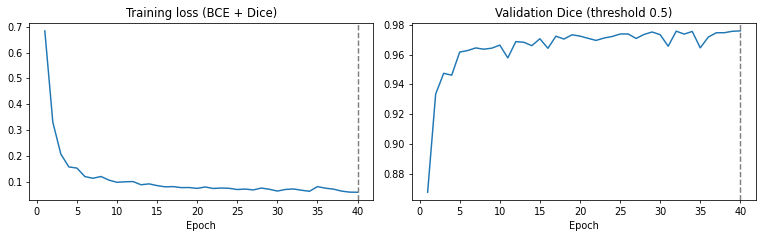

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["epoch"], history["train_loss"])
axes[0].set_title("Training loss (BCE + Dice)")
axes[1].plot(history["epoch"], history["val_dice"])
axes[1].set_title("Validation Dice (threshold 0.5)")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--")
    ax.set_xlabel("Epoch")
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_training_curves.png", dpi=150)
plt.show()

**Predicting at the original image size**

The best epoch's weights are loaded back. For each validation and test image the model gives a 256 x 256 probability map, which is resized back to the image's original size (about 800 x 540). This matters because the square resize stretches the head, and a circumference measured on the stretched mask would be wrong. The loader's return_meta=True option supplies the original size, the pixel size and the doctors' head circumference for each image.

From here on, Dice and IoU are computed at the original size against the saved masks from notebook 01, so they describe the masks that are actually measured.

In [12]:
model.load_state_dict(torch.load(checkpoint, map_location=device))
model.eval()

meta_loaders = get_dataloaders(DATA_DIR, image_size=IMAGE_SIZE,
                               batch_size=BATCH_SIZE, augment=False,
                               return_meta=True)
predictions = []   # one dict per image
with torch.no_grad():
    for split in ("val", "test"):
        for images, _, meta in meta_loaders[split]:
            probs = torch.sigmoid(model(images.to(device)))[:, 0].cpu().numpy()
            for i, prob in enumerate(probs):
                width = int(meta["original_width"][i])
                height = int(meta["original_height"][i])
                predictions.append({
                    "split": split,
                    "filename": meta["filename"][i],
                    "pixel_size_mm": float(meta["pixel_size_mm"][i]),
                    "true_hc_mm": float(meta["true_hc_mm"][i]),
                    # cv2.resize takes (width, height)
                    "prob": cv2.resize(prob, (width, height),
                                       interpolation=cv2.INTER_LINEAR),
                })
print(f"Predicted {len(predictions)} images "
      f"({sum(p['split'] == 'test' for p in predictions)} test)")

Predicted 299 images (149 test)


**From mask to millimetres**

This follows the same method notebook 01 used to check the masks, so the numbers are comparable:

1. Take the outer edge of the largest blob in the mask. Small stray blobs are ignored.
2. Drop edge points that lie on the image border, since a head cut off by the frame has a straight edge there that is not skull.
3. Fit an ellipse to the remaining points with OpenCV.
4. Turn the ellipse axes into a circumference with Ramanujan's approximation.
5. Multiply by the image's pixel size to get mm.

If a mask is empty or too small to fit an ellipse, the circumference is recorded as missing and counted below as a failed fit.

Notebook 01 found that the true filled masks read on average about 0.7 mm larger than the doctors' value, because the filled mask includes the width of the drawn line. A model trained on those masks should show a similar small positive bias.

In [13]:
def ellipse_circumference(semi_major, semi_minor):
    """Ramanujan's approximation of the circumference of an ellipse."""
    h = ((semi_major - semi_minor) / (semi_major + semi_minor)) ** 2
    return np.pi * (semi_major + semi_minor) * (
        1 + 3 * h / (10 + np.sqrt(4 - 3 * h)))


def mask_hc_mm(mask, pixel_size_mm):
    """Head circumference in mm from a 0/1 mask at the original size."""
    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return np.nan
    points = max(contours, key=cv2.contourArea).reshape(-1, 2)
    height, width = mask.shape
    inside = ((points[:, 0] > 0) & (points[:, 0] < width - 1)
              & (points[:, 1] > 0) & (points[:, 1] < height - 1))
    points = points[inside]
    if len(points) < 5:          # fitEllipse needs at least 5 points
        return np.nan
    _, axes, _ = cv2.fitEllipse(points)
    return ellipse_circumference(axes[0] / 2, axes[1] / 2) * pixel_size_mm


def score_images(predictions, threshold, split):
    """Dice, IoU and HC error for every image in one split."""
    rows = []
    for p in predictions:
        if p["split"] != split:
            continue
        pred = (p["prob"] >= threshold).astype(np.uint8)
        truth = (cv2.imread(str(MASK_DIR / p["filename"]),
                            cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        pred_hc = mask_hc_mm(pred, p["pixel_size_mm"])
        rows.append({
            "filename": p["filename"],
            "dice": dice_score(pred, truth),
            "iou": iou_score(pred, truth),
            "true_hc_mm": p["true_hc_mm"],
            "pred_hc_mm": pred_hc,
            "hc_error_mm": pred_hc - p["true_hc_mm"],
        })
    return pd.DataFrame(rows)

**Choosing the threshold on validation**

A pixel counts as head when its probability is at or above the threshold. The usual default is 0.5, but a slightly lower or higher cut-off can fit the skull edge better. Each threshold in THRESHOLDS is tried on the validation split only, and the one with the highest mean validation Dice is kept. The validation HC error is shown too, for information.

In [14]:
sweep = []
for threshold in THRESHOLDS:
    val = score_images(predictions, threshold, "val")
    sweep.append({
        "threshold": threshold,
        "val_dice": val["dice"].mean(),
        "val_iou": val["iou"].mean(),
        "val_hc_mae_mm": val["hc_error_mm"].abs().mean(),
    })
sweep = pd.DataFrame(sweep)
sweep.to_csv(RESULT_DIR / f"{MODEL_NAME}_threshold_sweep.csv", index=False)

best_threshold = float(sweep.loc[sweep["val_dice"].idxmax(), "threshold"])
print(f"Chosen threshold: {best_threshold}")
sweep.round(4)

Chosen threshold: 0.4


,threshold,val_dice,val_iou,val_hc_mae_mm
0,0.3,0.9759,0.9533,2.4626
1,0.4,0.9764,0.9542,2.0633
2,0.5,0.9763,0.9540,1.8681
3,0.6,0.9758,0.9531,1.8495
4,0.7,0.9746,0.9509,2.0932


**Scoring the test split, once**

Everything is now fixed: the weights from the best validation epoch and the threshold chosen on validation. The test split is scored once with those choices and nothing is changed afterwards, so the test numbers are a fair estimate of how the model does on new images.

The table reports:

- Mean Dice and IoU at the original image size.
- HC mean absolute error (MAE), the average size of the error in mm.
- HC mean signed error, which shows whether the model tends to read high (positive) or low (negative). About +0.7 mm is expected from the filled masks.
- HC MAE by head size group, because notebook 01 showed small heads have fainter skulls and fewer examples.
- Failed fits: test images where no ellipse could be fitted.

In [15]:
test = score_images(predictions, best_threshold, "test")
test["size_group"] = pd.cut(test["true_hc_mm"], bins=[0, 100, 200, 400],
                            labels=["under 100 mm", "100 to 200 mm",
                                    "over 200 mm"])
test.to_csv(RESULT_DIR / f"{MODEL_NAME}_test_per_image.csv", index=False)

summary = pd.Series({
    "best epoch": best_epoch,
    "threshold": best_threshold,
    "test images": len(test),
    "Dice (mean)": test["dice"].mean(),
    "IoU (mean)": test["iou"].mean(),
    "HC MAE (mm)": test["hc_error_mm"].abs().mean(),
    "HC mean signed error (mm)": test["hc_error_mm"].mean(),
    "HC median abs error (mm)": test["hc_error_mm"].abs().median(),
    "failed fits": int(test["pred_hc_mm"].isna().sum()),
})
summary.to_frame("value").to_csv(RESULT_DIR / f"{MODEL_NAME}_test_summary.csv")
print(summary.round(3).to_string())
print()
print(test.groupby("size_group", observed=False).agg(
    images=("filename", "size"),
    dice=("dice", "mean"),
    hc_mae_mm=("hc_error_mm", lambda e: e.abs().mean()),
).round(3).to_string())

best epoch                    40.000
threshold                      0.400
test images                  149.000
Dice (mean)                    0.974
IoU (mean)                     0.951
HC MAE (mm)                    2.315
HC mean signed error (mm)      1.215
HC median abs error (mm)       1.589
failed fits                    0.000

               images   dice  hc_mae_mm
size_group                             
under 100 mm       28  0.952      1.996
100 to 200 mm      89  0.980      1.964
over 200 mm        32  0.978      3.572


**Predicted against true head circumference**

Each point is one test image. Points on the gray diagonal are perfect measurements, and points above it are over-estimates. The right panel shows the error against head size, which makes it easy to see if the error grows with larger heads.

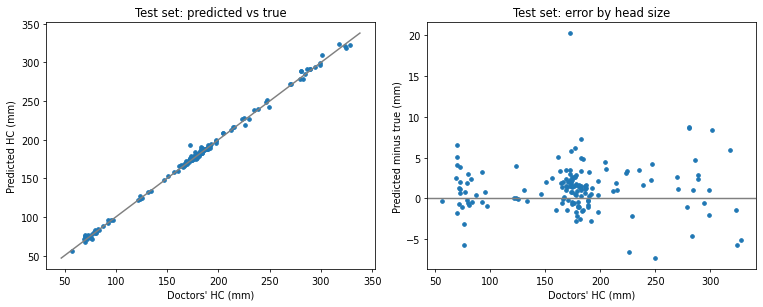

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(test["true_hc_mm"], test["pred_hc_mm"], s=14)
limits = [test["true_hc_mm"].min() - 10, test["true_hc_mm"].max() + 10]
axes[0].plot(limits, limits, color="gray")
axes[0].set_xlabel("Doctors' HC (mm)")
axes[0].set_ylabel("Predicted HC (mm)")
axes[0].set_title("Test set: predicted vs true")
axes[1].scatter(test["true_hc_mm"], test["hc_error_mm"], s=14)
axes[1].axhline(0, color="gray")
axes[1].set_xlabel("Doctors' HC (mm)")
axes[1].set_ylabel("Predicted minus true (mm)")
axes[1].set_title("Test set: error by head size")
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_hc_scatter.png", dpi=150)
plt.show()

**Best and worst test images**

Green is the doctors' outline (from the notebook 01 mask) and red is the model. The top row shows the four test images with the highest Dice and the bottom row the four with the lowest. The bottom row shows where the model struggles, for example faint skull edges, heads cut off by the frame, or other bright curves that the model mistakes for skull.

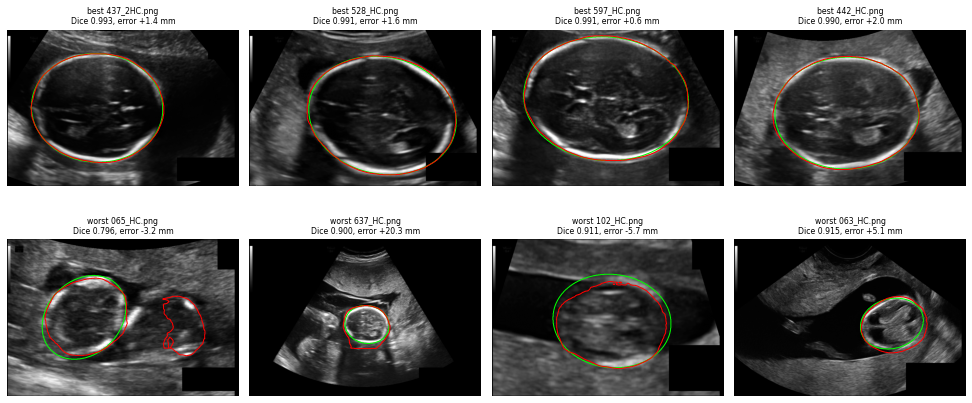

In [17]:
def show_cases(rows, title_prefix, axes_row):
    for ax, row in zip(axes_row, rows.itertuples()):
        image = cv2.imread(str(IMAGE_DIR / row.filename), cv2.IMREAD_GRAYSCALE)
        truth = cv2.imread(str(MASK_DIR / row.filename), cv2.IMREAD_GRAYSCALE)
        prob = next(p["prob"] for p in predictions
                    if p["filename"] == row.filename)
        ax.imshow(image, cmap="gray")
        ax.contour(truth, levels=[127], colors="lime", linewidths=1)
        ax.contour(prob >= best_threshold, levels=[0.5], colors="red",
                   linewidths=1)
        ax.set_title(f"{title_prefix} {row.filename}\nDice {row.dice:.3f}, "
                     f"error {row.hc_error_mm:+.1f} mm", fontsize=8)
        ax.axis("off")


fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
show_cases(test.nlargest(4, "dice"), "best", axes[0])
show_cases(test.nsmallest(4, "dice"), "worst", axes[1])
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_best_worst_test.png", dpi=150)
plt.show()

**Saving the predicted masks**

The predicted masks for validation and test are saved at the original image size as 0/255 PNGs, the same format as the masks from notebook 01, so the measurement notebook can read them the same way. They go to *results/pred_masks/unet_plain/* in the shared Drive folder, next to the per-image CSV and the summary table.

In [18]:
pred_dir = RESULT_DIR / "pred_masks" / MODEL_NAME
pred_dir.mkdir(parents=True, exist_ok=True)
for p in predictions:
    mask = (p["prob"] >= best_threshold).astype(np.uint8) * 255
    cv2.imwrite(str(pred_dir / p["filename"]), mask)

print(f"Model weights:   {checkpoint}")
print(f"Predicted masks: {pred_dir} ({len(predictions)} files)")
print(f"Tables:          {RESULT_DIR}")
print(f"Figures:         {FIGURE_DIR}")

Model weights:   /content/drive/MyDrive/aai-521-hc18/models/unet_plain.pt
Predicted masks: /content/drive/MyDrive/aai-521-hc18/results/pred_masks/unet_plain (299 files)
Tables:          /content/drive/MyDrive/aai-521-hc18/results
Figures:         /content/drive/MyDrive/aai-521-hc18/figures
